# 01 · Fase A — Desmontaje instrumentado de SAM 2 congelado

**Lo que pide la tarea** (Fase A): *no* limitarse a ejecutar el modelo, sino abrirlo.

| requerido | dónde está aquí |
|---|---|
| recuento de parámetros y FLOPs por bloque | §1 (parámetros), §3 (coste computacional) |
| visualización de características intermedias | §4 (codificador), §5 (decodificador) |
| mapa de campo receptivo | §6 |
| medición de latencia / memoria | §7 |

Objetivo: *entender por qué el modelo tiene la forma que tiene.* La tarea también destaca el
**decodificador de máscaras** — su atención prompt→imagen, sus tokens de salida y cómo decide la
máscara — por lo que §3 y §5 profundizan en el decodificador.

**Cómo está organizado este notebook.** La maquinaria de medición vive en `src/teardown.py`
(recuento de parámetros, conteo de MACs mediante hooks, captura de activaciones, campo receptivo
efectivo, medición de tiempos) para que sea reutilizable y verificable. Este notebook la llama,
explica qué significa cada número y lo representa gráficamente.

**Nada de aquí modifica el modelo.** Toda medición es instrumentación sobre la red congelada. Es
deliberado: la Fase A debe caracterizar la *línea base* sobre la que interviene la Fase B.

Las cifras absolutas dependen de la máquina (CUDA / MPS / CPU); lo importante es el panorama
*relativo* — qué bloque domina, cuánto cuesta un prompt.


## 0. Configuración

Ponemos `src/` en el path para poder importar los módulos del propio proyecto, y después cargamos
el modelo congelado. `build_model` lee el checkpoint de `checkpoints/` y desactiva el seguimiento
de gradientes, porque aquí nunca entrenamos.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

# Locate the repo root regardless of where the notebook is launched from.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from sam2_auto_segment import build_mask_generator, build_model, get_device
from sam2.sam2_image_predictor import SAM2ImagePredictor
import teardown as td

print("device:", get_device())

device: mps


## 1. El modelo en conjunto

Primera pregunta: ¿dónde viven realmente los parámetros? El "tamaño" de un modelo suele citarse
como un solo número, pero ese número es la suma de partes muy desiguales — y la forma en que se
reparte nos dice cómo está pensada su arquitectura para usarse.


In [2]:
model = build_model()
total = td.params_of(model)
print(f"total parameters: {total / 1e6:.2f} M")
print(f"running on      : {model.device}")

total parameters: 46.06 M
running on      : mps:0


In [3]:
blocks = pd.DataFrame(td.children_table(model))
blocks["params_M"] = blocks["params_M"].round(3)
blocks["share_pct"] = blocks["share_pct"].round(1)
blocks

,block,type,params_M,share_pct
0,image_encoder,ImageEncoder,34.317,74.5
1,mask_downsample,Conv2d,0.000,0.0
2,memory_attention,MemoryAttention,5.922,12.9
3,memory_encoder,MemoryEncoder,1.385,3.0
4,sam_prompt_encoder,PromptEncoder,0.006,0.0
5,sam_mask_decoder,MaskDecoder,4.215,9.2
6,obj_ptr_proj,MLP,0.197,0.4
7,obj_ptr_tpos_proj,Linear,0.016,0.0


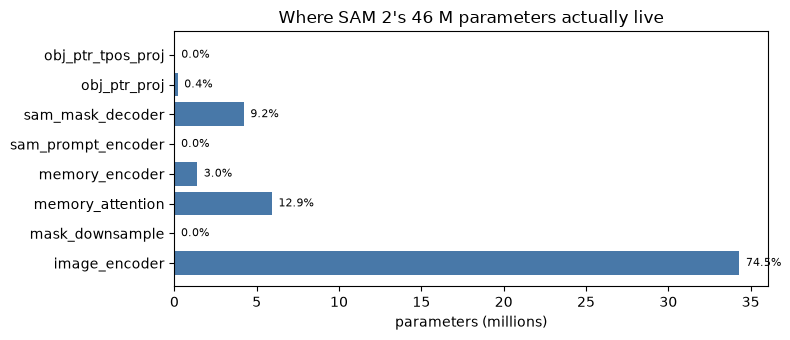

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(blocks["block"], blocks["params_M"], color="#4878a8")
for y, (value, share) in enumerate(zip(blocks["params_M"], blocks["share_pct"])):
    ax.text(value + 0.4, y, f"{share:.1f}%", va="center", fontsize=8)
ax.set_xlabel("parameters (millions)")
ax.set_title("Where SAM 2's 46 M parameters actually live")
plt.tight_layout()
plt.show()

**Lectura.** Tres hechos, cada uno de los cuales explica una decisión de diseño:

1. **~74 % de los parámetros son el codificador de imagen** (34.3 M). Como en casi todo sistema
   de visión, el aprendizaje de representaciones es la parte cara.
2. **El decodificador de máscaras es solo el 9 %** (4.2 M). No es casualidad: SAM se diseñó para
   que el decodificador pueda **reejecutarse barato muchas veces, una por prompt**, contra un
   único embedding de imagen (caro). Es exactamente la suposición que nuestro proyecto pone a
   prueba en modo sin prompts.
3. **~16 % de los parámetros sirven al vídeo, no a las imágenes** — `memory_attention` (5.9 M) y
   `memory_encoder` (1.4 M). SAM 2 extendió SAM para el seguimiento de vídeo; en segmentación de
   una sola imagen (toda nuestra tarea) nunca se ejecutan. Así que citar "46 M" exagera en ~16 %
   lo que realmente usamos.

Vale la pena afirmar el punto 3 con claridad en el informe: una parte considerable de la
capacidad de este modelo está inactiva en nuestra tarea, y ser honestos sobre ello es más barato
que dejarse pillar en la defensa oral.


## 2. Dentro del codificador de imagen

El codificador es un backbone **Hiera** (un transformer de visión jerárquico) más un pequeño
cuello **FPN** que reforma sus características en la pirámide multiescala que consume el
decodificador. También desglosamos aquí el decodificador en sus partes, ya que ese es el bloque
que tocará la Fase B.


In [5]:
encoder = model.image_encoder
print("image_encoder:", type(encoder).__name__)
print(f"  trunk (Hiera) : {td.params_of(encoder.trunk) / 1e6:7.3f} M")
print(f"  neck  (FPN)   : {td.params_of(encoder.neck) / 1e6:7.3f} M")

image_encoder: ImageEncoder
  trunk (Hiera) :  33.947 M
  neck  (FPN)   :   0.370 M


In [6]:
print("-- mask decoder, broken down --")
print(pd.DataFrame(td.children_table(model.sam_mask_decoder)).round(4).to_string(index=False))
print()
print("transformer_dim:", model.sam_mask_decoder.transformer_dim)
print("num mask tokens:", model.sam_mask_decoder.num_mask_tokens)

-- mask decoder, broken down --
                    block              type  params_M  share_pct
              transformer TwoWayTransformer    3.2913    78.0825
                iou_token         Embedding    0.0003     0.0061
              mask_tokens         Embedding    0.0010     0.0243
          obj_score_token         Embedding    0.0003     0.0061
         output_upscaling        Sequential    0.0740     1.7545
                  conv_s0            Conv2d    0.0082     0.1951
                  conv_s1            Conv2d    0.0164     0.3902
output_hypernetworks_mlps        ModuleList    0.5592    13.2673
      iou_prediction_head               MLP    0.1326     3.1461
      pred_obj_score_head               MLP    0.1318     3.1278

transformer_dim: 256
num mask tokens: 4


**Lectura.** El cuello FPN es minúsculo (0.37 M); solo proyecta y fusiona. Dentro del
decodificador domina el **transformer bidireccional** (3.29 M) y las dos cabezas de calidad son
~0.13 M cada una. Así que la capacidad del decodificador reside en la **atención cruzada entre
los tokens de prompt y las características de imagen** — precisamente el mecanismo que la tarea
nos pide analizar. Fíjate en que el decodificador lleva 4 tokens de máscara: propone varias
máscaras por prompt y las puntúa, de ahí viene `multimask_output`.


## 3. Cuánto cuesta ejecutarlo — y el *coste del prompt*

El número de parámetros es *tamaño*; lo que cuesta tiempo de reloj es el *cómputo*. Contamos
multiplicaciones-acumulaciones (MACs) con hooks en cada `Conv2d` y `Linear`
(`teardown.count_macs`), así que estos números están medidos, no estimados.

La comparación que importa es **una codificación de imagen frente a una decodificación de
prompt**, porque el diseño de SAM 2 asume que la primera se paga una vez y la segunda
repetidamente.


In [7]:
# 1024x1024 is the size SAM 2 resizes every input to internally.
x1024 = torch.zeros(1, 3, 1024, 1024, device=model.device)

encoder_macs = td.count_macs(model.image_encoder, x1024)
print(f"image encoder : {encoder_macs / 1e9:9.2f} G MACs  (per image, paid once)")

image encoder :    133.59 G MACs  (per image, paid once)


In [8]:
# A real, field-rich patch from our dataset. We feed the native 366x366 image so the
# predicted masks line up pixel-for-pixel with the parcel map.
PATCH = "2019_31TDK_patch_25_00"
image = np.array(Image.open(ROOT / "data/processed" / f"{PATCH}_rgb.png").convert("RGB"))
parcels = np.load(ROOT / "data/processed" / f"{PATCH}_parcels.npy")
print("image", image.shape, "| parcels", parcels.shape,
      "| fields:", len(np.unique(parcels)) - 1)

predictor = SAM2ImagePredictor(model)
predictor.set_image(image)                            # this runs the encoder once

point = np.array([[183.0, 183.0]], dtype=np.float32)  # one "click" in the middle
label = np.array([1])

decoder_macs = td.count_macs(
    model.sam_mask_decoder,
    run=lambda: predictor.predict(point_coords=point, point_labels=label, multimask_output=False))
prompt_macs = td.count_macs(
    model.sam_prompt_encoder,
    run=lambda: predictor.predict(point_coords=point, point_labels=label, multimask_output=False))

print(f"prompt encoder: {prompt_macs / 1e9:9.4f} G MACs  (per prompt - negligible)")
print(f"mask decoder  : {decoder_macs / 1e9:9.4f} G MACs  (per prompt)")

image (366, 366, 3) | parcels (366, 366) | fields: 466


prompt encoder:    0.0000 G MACs  (per prompt - negligible)
mask decoder  :    1.3666 G MACs  (per prompt)


In [9]:
# Prompt-free mode decodes a GRID of points, one prompt at a time. That is where the cost piles up.
rows = []
for pps in (16, 32):
    prompts = pps ** 2
    decoder_total = prompts * decoder_macs
    rows.append({
        "points_per_side": pps,
        "decoder calls": prompts,
        "encoder G MACs": round(encoder_macs / 1e9, 2),
        "decoder G MACs": round(decoder_total / 1e9, 2),
        "decoder / encoder": round(decoder_total / encoder_macs, 2),
    })
cost = pd.DataFrame(rows)
cost

,points_per_side,decoder calls,encoder G MACs,decoder G MACs,decoder / encoder
0,16,256,133.59,349.85,2.62
1,32,1024,133.59,1399.39,10.48


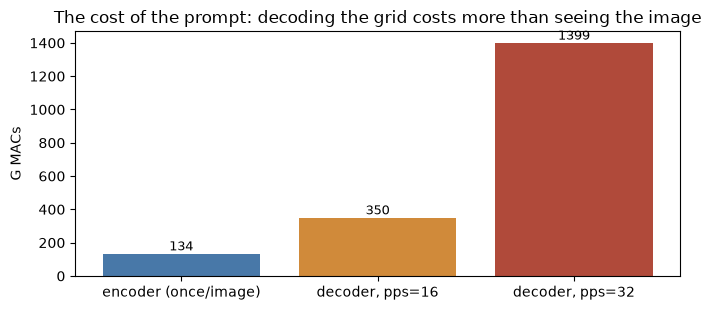

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.2))
labels = ["encoder (once/image)", "decoder, pps=16", "decoder, pps=32"]
values = [encoder_macs / 1e9, cost.loc[0, "decoder G MACs"], cost.loc[1, "decoder G MACs"]]
ax.bar(labels, values, color=["#4878a8", "#d08a3a", "#b04a3a"])
for i, value in enumerate(values):
    ax.text(i, value + 20, f"{value:.0f}", ha="center", fontsize=9)
ax.set_ylabel("G MACs")
ax.set_title("The cost of the prompt: decoding the grid costs more than seeing the image")
plt.tight_layout()
plt.show()

**Lectura — esta es la medición estrella del proyecto.** El codificador cuesta ~134 G MACs
por imagen; el decodificador cuesta ~1.4 G MACs **por prompt**. Por prompt eso es minúsculo, que
es la intención del diseño. El problema es que la segmentación sin prompts pide una
decodificación por punto de la rejilla:

- `points_per_side=16` → 256 prompts → ~350 G MACs ≈ **2.6× el codificador**
- `points_per_side=32` → 1024 prompts → ~1400 G MACs ≈ **10× el codificador**

Así que *eliminar* el prompt humano no elimina el *coste* del prompt — reemplaza un clic bien
colocado por una rejilla mecánica, y esa rejilla pasa a ser el cómputo dominante. Esa es la
respuesta cuantitativa a la pregunta del tema (*"el coste del prompt en SAM"*). También explica
una elección que hicimos en la línea base: `points_per_side=16`, porque 32 habría sido ~3× más
lento para poca ganancia.


## 4. Características intermedias — lo que el codificador realmente ve

Ahora abrimos la caja negra: pasamos una imagen real por el codificador y miramos los mapas de
características en cada etapa. Un mapa de características tiene cientos de canales, así que
tomamos sus **tres primeras componentes principales** y las mapeamos a R/G/B
(`teardown.pca_rgb`) — una forma estándar de hacer visible un tensor de activaciones de alta
dimensión.

El tronco Hiera es jerárquico, así que sus etapas se reducen en espacio y crecen en canales.
Capturamos la salida del tronco para obtener las cuatro etapas a la vez.


In [11]:
# A tensorial copy of the same patch, resized to the 1024 px SAM 2 works at.
tensor = torch.from_numpy(image).permute(2, 0, 1)[None].float() / 255.0
tensor = torch.nn.functional.interpolate(tensor, size=(1024, 1024), mode="bilinear",
                                         align_corners=False).to(model.device)

captured = td.capture(model.image_encoder, tensor, targets={"trunk": encoder.trunk})
stages = captured["trunk"]           # list of 4 tensors, finest -> coarsest
for i, feat in enumerate(stages):
    print(f"stage {i}: {tuple(feat.shape)}  (stride {1024 // feat.shape[-1]:>2})")

stage 0: (1, 96, 256, 256)  (stride  4)
stage 1: (1, 192, 128, 128)  (stride  8)
stage 2: (1, 384, 64, 64)  (stride 16)
stage 3: (1, 768, 32, 32)  (stride 32)


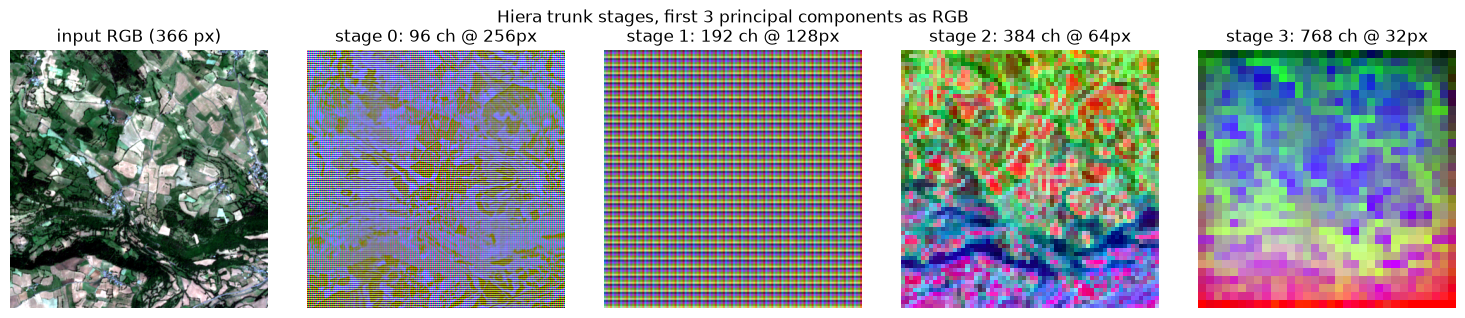

In [12]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
axes[0].imshow(image)
axes[0].set_title("input RGB (366 px)")
for i, feat in enumerate(stages):
    f = feat[0].detach().cpu().numpy()
    axes[i + 1].imshow(td.pca_rgb(f))
    axes[i + 1].set_title(f"stage {i}: {f.shape[0]} ch @ {f.shape[1]}px")
for ax in axes:
    ax.axis("off")
plt.suptitle("Hiera trunk stages, first 3 principal components as RGB")
plt.tight_layout()
plt.show()

**Lectura.** La pirámide es exactamente lo que quiere un modelo de segmentación: las etapas
finas (256 px) conservan el detalle de alta frecuencia que necesitan los *límites* de los campos,
mientras que las etapas gruesas (32 px) llevan el contexto de gran escala que dice "esto es
tierra de cultivo, no una ciudad". Las vistas PCA muestran que la estructura se concentra en los
bordes de las parcelas y las carreteras — es decir, el codificador ya ha aprendido a responder a
los límites de campo, aunque nunca se entrenó con imágenes de satélite. Eso es alentador para el
método y es justo el tipo de evidencia que el informe debe mostrar en lugar de afirmar.


## 5. Dentro del decodificador de máscaras — de un prompt a una máscara

La tarea pregunta explícitamente cómo el decodificador convierte un prompt en una máscara.
Concretamente, `MaskDecoder` (ver `sam2/modeling/sam/mask_decoder.py`) hace:

1. construir una secuencia de tokens: `[iou_token, mask_tokens × 4, sparse prompt embeddings]` y
   sumar el embedding **denso** del prompt al embedding de imagen;
2. ejecutar el **transformer bidireccional**, que deja que los tokens del prompt atiendan a la
   imagen y que la imagen atienda de vuelta (`hs, src = transformer(src, pos_src, tokens)`) —
   esta es la "atención prompt→imagen";
3. tomar los `mask_tokens` transformados y pasarlos por MLPs por token para obtener un vector de
   pesos de **hiperred**;
4. multiplicar ese vector con el embedding de imagen reescalado:
   `masks = hyper_in @ upscaled_embedding`. La máscara se produce, por tanto, con pesos
   *dinámicos* generados a partir del token, no con una cabeza de clasificación fija — y la rama
   `iou_token` predice la calidad de la máscara.

Veamos que esto ocurre en un campo real. Hacemos un prompt en el centroide de una parcela grande
y comparamos el resultado con la verdad de referencia.


In [13]:
# Pick the largest field in the patch and click at its centre of mass.
sizes = [(int(pid), int((parcels == pid).sum())) for pid in np.unique(parcels) if pid != 0]
target_id, target_px = max(sizes, key=lambda t: t[1])
ys, xs = np.where(parcels == target_id)
click = np.array([[float(xs.mean()), float(ys.mean())]], dtype=np.float32)
print(f"prompting at ({click[0,0]:.0f}, {click[0,1]:.0f}) for field {target_id} "
      f"({target_px} px)")

prompting at (97, 92) for field 9877413 (2164 px)


In [14]:
mask, score, _ = predictor.predict(point_coords=click, point_labels=np.array([1]),
                                   multimask_output=False)
mask = np.squeeze(mask).astype(bool)
truth = parcels == target_id
iou = (mask & truth).sum() / (mask | truth).sum()
print(f"predicted IoU score (what the decoder believes): {float(np.ravel(score)[0]):.3f}")
print(f"actual IoU against the ground-truth field     : {iou:.3f}")
print(f"predicted mask covers {mask.mean()*100:.1f}% of the patch")

predicted IoU score (what the decoder believes): 0.703
actual IoU against the ground-truth field     : 0.301
predicted mask covers 0.9% of the patch


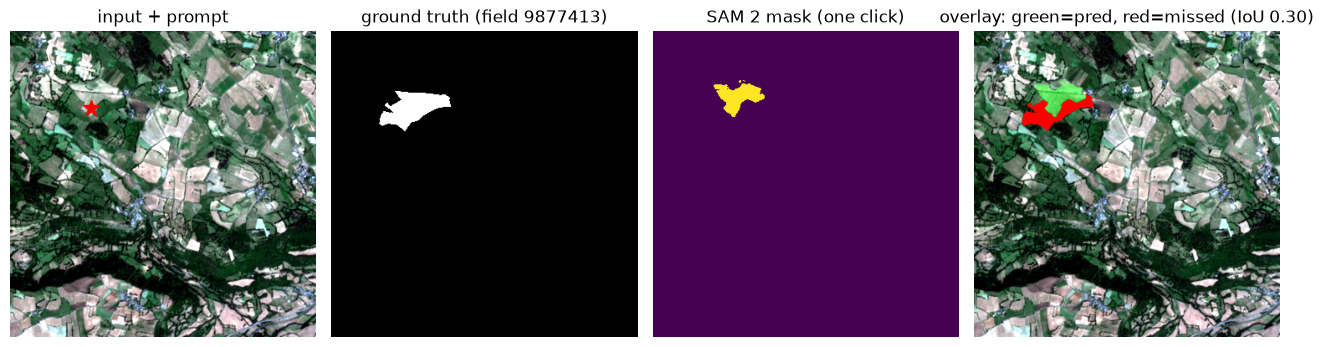

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
axes[0].imshow(image); axes[0].set_title("input + prompt")
axes[0].plot(click[0, 0], click[0, 1], "r*", markersize=12)
axes[1].imshow(truth, cmap="gray"); axes[1].set_title(f"ground truth (field {target_id})")
axes[2].imshow(mask, cmap="viridis"); axes[2].set_title("SAM 2 mask (one click)")
overlay = image.copy()
overlay[truth & ~mask] = [255, 0, 0]
overlay[mask] = (0.5 * overlay[mask] + 0.5 * np.array([0, 255, 0])).astype(np.uint8)
axes[3].imshow(overlay); axes[3].set_title(f"overlay: green=pred, red=missed (IoU {iou:.2f})")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

transformer token output hs : (1, 8, 256) (iou + 4 mask tokens + 1 prompt = 6)
transformer image output src: (1, 4096, 256) -> reshaped to the 64x64 embedding
upscaled embedding          : (1, 32, 256, 256) (multiplied by the hypernetwork)


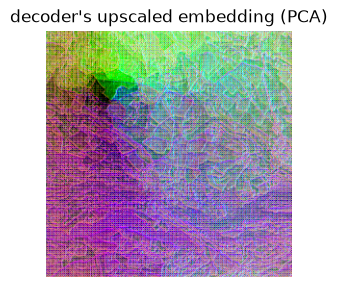

In [16]:
# Look at what the decoder receives and produces along the way.
# Careful: `output_upscaling` is NOT called as a single module here -- the image predictor
# hands the decoder high-resolution features, so the decoder runs those sub-layers
# individually and fuses the encoder's skip connections in. We therefore hook the last
# activation of that sequence: it holds the embedding the hypernetwork multiplies.
final_upscale = list(model.sam_mask_decoder.output_upscaling)[-1]
inner = td.capture(model.sam_mask_decoder,
                   run=lambda: predictor.predict(point_coords=click,
                                                 point_labels=np.array([1]),
                                                 multimask_output=False),
                   targets={"transformer": model.sam_mask_decoder.transformer,
                            "upscaled": final_upscale})
hs, src = inner["transformer"]
print("transformer token output hs :", tuple(hs.shape), "(iou + 4 mask tokens + 1 prompt = 6)")
print("transformer image output src:", tuple(src.shape), "-> reshaped to the 64x64 embedding")

upscaled = inner["upscaled"]
print("upscaled embedding          :", tuple(upscaled.shape), "(multiplied by the hypernetwork)")
plt.figure(figsize=(3.2, 3.2))
plt.imshow(td.pca_rgb(upscaled[0].detach().cpu().numpy()))
plt.title("decoder's upscaled embedding (PCA)")
plt.axis("off")
plt.show()

**Lectura.** El prompt es un token; el decodificador pasa 6 tokens por el transformer
bidireccional contra un embedding de imagen de 64×64, y luego una hiperred convierte los tokens
de máscara en pesos de máscara. Un solo clic ya produce una máscara que es *aproximadamente* el
campo correcto, pero la superposición muestra el modo de fallo que nuestra línea base midió a
escala: la máscara suele **sobrepasar o fusionar parcelas vecinas** (rojo = píxeles de la verdad
de referencia que la máscara no cubrió, porque se desbordó a la de al lado). Fíjate también en la
brecha entre la confianza del propio decodificador (puntuación IoU) y el IoU real — la
autoevaluación del modelo es optimista, lo que importa cuando el generador automático *filtra
máscaras por esa puntuación predicha*.

Ese es el mecanismo en el que intervendrá la Fase B: todo lo anterior ocurre en 4.2 M de
parámetros que consumen un embedding de imagen fijo.


## 6. Campo receptivo

¿Cuánto de la imagen puede "ver" un píxel de salida? Medimos el **campo receptivo efectivo**:
introducimos una imagen de ceros con `requires_grad=True`, tomamos un píxel del mapa de
características más profundo del codificador y retropropagamos. El gradiente respecto a la
entrada nos dice qué píxeles de entrada influyeron en ese píxel de salida — un ERF puramente
empírico, sin suposiciones arquitectónicas.

`teardown.erf_extent` informa entonces de la longitud del lado de la región que contiene el
10 % / 50 % de la masa total del ERF, lo que convierte la imagen en dos números.


In [17]:
erf = td.effective_receptive_field(model.image_encoder, size=1024)
print(f"ERF map: {erf.shape}")
print(f"extent holding 10% of the mass: {td.erf_extent(erf, 0.10):>4} px of 1024")
print(f"extent holding 50% of the mass: {td.erf_extent(erf, 0.50):>4} px of 1024")

ERF map: (1024, 1024)
extent holding 10% of the mass:   15 px of 1024
extent holding 50% of the mass:  150 px of 1024


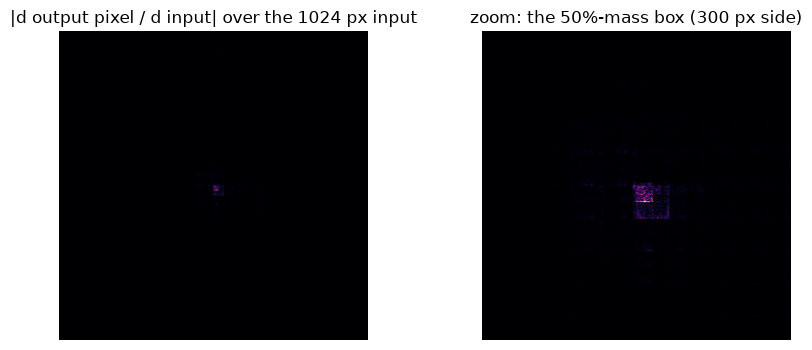

In [18]:
center = np.array(erf.shape) // 2
extent50 = td.erf_extent(erf, 0.50)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
axes[0].imshow(erf, cmap="inferno")
axes[0].set_title("|d output pixel / d input| over the 1024 px input")
axes[1].imshow(erf[center[0]-extent50:center[0]+extent50, center[1]-extent50:center[1]+extent50],
               cmap="inferno")
axes[1].set_title(f"zoom: the 50%-mass box ({2*extent50} px side)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Lectura.** El ERF es una mancha difusa, no un cuadrado duro: ~10 % de la influencia está
en un vecindario pequeño, mientras que la mitad se extiende por un área mucho mayor. Ese es el
comportamiento que se espera de un transformer profundo con atención global — y es *buena noticia
para nuestra tarea*, porque decidir si unos píxeles pertenecen al mismo campo se beneficia del
contexto de largo alcance, no solo de la textura local. También significa que un parche de 366 px
está cómodamente dentro del alcance contextual del modelo, así que recortar no lo está dejando
sin contexto.


## 7. Latencia y memoria

El coste en MACs no es lo mismo que el tiempo. Aquí medimos la latencia real de reloj en la GPU
de esta máquina (CUDA / MPS) y la memoria del acelerador en uso, para las tres pasadas que
componen nuestra tubería.


In [19]:
encoder_time = td.time_forward(model.image_encoder, x1024, repeats=3)
decoder_time = td.time_call(
    lambda: predictor.predict(point_coords=point, point_labels=label, multimask_output=False),
    repeats=5)
set_image_time = td.time_call(lambda: predictor.set_image(image), repeats=3)

print(f"encoder forward (1024 px)        : {encoder_time*1000:7.1f} ms per image")
print(f"predictor.set_image (incl. encode): {set_image_time*1000:7.1f} ms per image")
print(f"one prompt -> one mask            : {decoder_time*1000:7.1f} ms")

encoder forward (1024 px)        :   423.6 ms per image
predictor.set_image (incl. encode):   623.9 ms per image
one prompt -> one mask            :    77.4 ms


In [20]:
# The full prompt-free pipeline, as used in the baseline: a 16x16 grid of prompts.
generator = build_mask_generator(model, points_per_side=16,
                                 pred_iou_thresh=0.5, stability_score_thresh=0.8)
gen_time = td.time_call(lambda: generator.generate(image), repeats=3)
prompts = 16 ** 2

timings = pd.DataFrame([
    {"stage": "encoder (per image)", "seconds": round(encoder_time, 3)},
    {"stage": "1 prompt (per prompt)", "seconds": round(decoder_time, 3)},
    {"stage": f"automatic pps=16 ({prompts} prompts)", "seconds": round(gen_time, 3)},
])
print(timings.to_string(index=False))
print(f"effective time per prompt inside the batch pipeline: "
      f"{gen_time / prompts * 1000:.1f} ms")
print(f"accelerator memory now: {td.allocated_memory_mb():.0f} MiB "
      f"(driver reserved {td.driver_memory_mb():.0f} MiB)")

                         stage  seconds
           encoder (per image)    0.424
         1 prompt (per prompt)    0.077
automatic pps=16 (256 prompts)    4.694
effective time per prompt inside the batch pipeline: 18.3 ms
accelerator memory now: 494 MiB (driver reserved 7862 MiB)


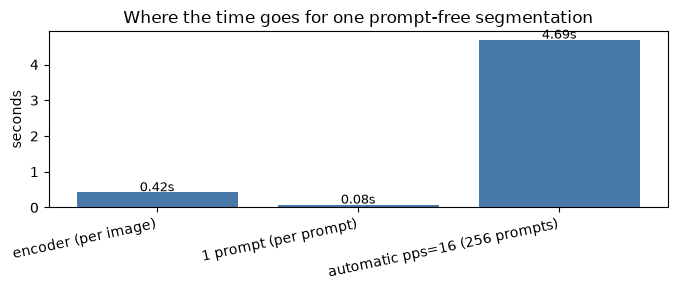

In [21]:
fig, ax = plt.subplots(figsize=(7, 3.0))
ax.bar(timings["stage"], timings["seconds"], color="#4878a8")
for i, value in enumerate(timings["seconds"]):
    ax.text(i, value + 0.03, f"{value:.2f}s", ha="center", fontsize=9)
ax.set_ylabel("seconds")
ax.set_title("Where the time goes for one prompt-free segmentation")
plt.xticks(rotation=12, ha="right")
plt.tight_layout()
plt.show()

**Lectura.** Un solo prompt es rápido — decenas de milisegundos, y esa cifra incluye el
sobrecoste de Python y de postprocesado de máscaras de una llamada `predict()`, no solo el
decodificador. La segmentación sin prompts hace *cientos* de ellas, así que la pasada automática
cuesta segundos: aproximadamente un orden de magnitud más que codificar la imagen una vez. El
generador **agrupa** sus prompts (`points_per_batch`), por eso su tiempo efectivo por prompt es
menor que el de una llamada `predict()` aislada — el agrupado es la única razón por la que una
rejilla densa es asequible.

Esto coincide con los recuentos de MACs, y explica dos elecciones que ya hicimos: la línea base
corre a `points_per_side=16`, y la evaluación de 888 parches tarda decenas de minutos en lugar de
segundos. También enmarca el lado práctico de la Fase B: cualquier cosa que reduzca el número de
llamadas al decodificador, o el coste de cada una, gana tiempo real — y este arnés puede medir si
lo hizo.


## 8. Resumen — por qué tiene la forma que tiene

| pregunta | respuesta medida |
|---|---|
| ¿Dónde viven los parámetros? | 74 % codificador de imagen, 9 % decodificador de máscaras, 16 % módulos de vídeo inactivos |
| ¿Qué domina el cómputo? | el decodificador, una vez por prompt: 2.6× el codificador con pps=16, ~10× con pps=32 |
| ¿Ve el codificador los límites de campo? | sí — la PCA de las etapas del tronco resalta bordes de parcelas y carreteras |
| ¿Cómo produce una máscara el decodificador? | 6 tokens por un transformer bidireccional, luego una hiperred derivada del token multiplica el embedding de imagen |
| ¿Hasta dónde ve un píxel de salida? | una mancha difusa: ~10 % de influencia local, el 50 % se extiende mucho más (el contexto de largo alcance es real) |
| ¿Cuánto cuesta en tiempo? | ~0.5 s codificar una imagen; segundos para una pasada sin prompts completa |

**La conclusión que pasa a la Fase B.** La asimetría de SAM 2 es deliberada: un codificador de
imagen caro cuyo embedding se reutiliza, y un decodificador barato pensado para llamarse muchas
veces. La segmentación sin prompts rompe la suposición detrás de esa economía — llama al módulo
barato cientos de veces por imagen, por lo que el "coste del prompt" acaba siendo mayor que el
coste de *ver*. La Fase B debería, por tanto, intervenir donde ese coste y ese mecanismo se
encuentran: el **decodificador de máscaras**.

**Dónde se usó asistencia de IA.** La instrumentación en `src/teardown.py` y la estructura de
este notebook se redactaron con un asistente de IA; cada número que contiene se produce
ejecutando el código de arriba en esta máquina, y cada interpretación es del equipo. Registrado
en `docs/decisions_es.md`.
